# Additional benchmark results and Experiments

Complements `benchmark_results.ipynb`. Every number is on the 1 000 test campaigns of the scenario concerned (environment
seeds 0–999; randomised policy seeds used policy_seed = env_seed + 1000), so differences are paired; ± values are 95% confidence intervals.
RL algorithms: mean of their 3 trainings per campaign, with the range of the 3 training means in brackets.
"Best α / b / τ" baselines are tuned on the test campaigns themselves (optimistic for these baselines).

Table of Content :

1. Decision time
2. MPC with an imperfect value estimate
3. Immediate rewards
4. Saturation and recency
5. Effective frequency and reminder
6. Valuation-head architecture

Data: `benchmark/benchmark_results/additional/`. Figures: saved to `figures/additional-exp/`.

In [1]:
import json
import numpy as np
import pandas as pd
from IPython.display import display

D = "benchmark_results/additional"
R = pd.read_csv(f"{D}/rewards.csv")
_missing = json.load(open(f"{D}/manifest.json"))["missing_or_incomplete"]
if _missing:
    print("Not available yet:\n  " + "\n  ".join(_missing))


def ci95(x):
    return 1.96 * np.std(x, ddof=1) / np.sqrt(len(x))


def scores(experiment):
    # episode reward per campaign for each algorithm; RL: mean of the 3 trainings (incomplete RL runs are skipped)
    S, spread = {}, {}
    for name, g in R[R["experiment"] == experiment].groupby("algorithm", sort=False):
        if g["training"].notna().any():
            piv = g.pivot(index="seed", columns="training", values="reward")
            if piv.shape[1] == 3:
                S[name], spread[name] = piv.mean(axis=1), (piv.mean().min(), piv.mean().max())
        else:
            S[name] = g.set_index("seed")["reward"].sort_index()
    return S, spread


def find(S, prefix):
    return next((k for k in S if k.startswith(prefix)), None)


def table(experiment, refs, gain=False):
    S, spread = scores(experiment)
    refs = [r for r in (find(S, p) for p in refs) if r]
    dp, fipla = find(S, "DP optimum"), find(S, "FiPla")
    rows = []
    for name, r in S.items():
        row = {"algorithm": name + (f"  [{spread[name][0]:.2f} – {spread[name][1]:.2f}]" if name in spread else ""),
               "mean reward": f"{r.mean():.3f} ± {ci95(r):.3f}", "_m": r.mean()}
        for ref in refs:
            if ref != name:
                d = r - S[ref]
                row[f"Δ vs {ref}"] = f"{d.mean():+.3f} ± {ci95(d):.3f}"
        if gain and dp and fipla:
            row["share of the DP gain over FiPla"] = f"{100 * (r.mean() - S[fipla].mean()) / (S[dp].mean() - S[fipla].mean()):+.0f}%"
        rows.append(row)
    return pd.DataFrame(rows).sort_values("_m", ascending=False).drop(columns="_m").set_index("algorithm").fillna("—")


import os
import re
import matplotlib.pyplot as plt

FIG = "../figures/additional-exp"
os.makedirs(FIG, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 9, "legend.fontsize": 7})
COL = {"DP optimum": "#222222", "MPCTimeBinned": "#7b4fb3", "MPC": "#2a6fdb", "Shading": "#e0731f", "FiPla": "#8a8a8a",
       "Constant": "#9467bd", "PPO": "#2e9e5b", "TD3": "#c0392b", "SAC": "#c9a227", "GreedyMyopic": "#d16ba5",
       "Cooldown": "#8c564b"}


def color(name):
    return next((c for k, c in COL.items() if name.startswith(k)), "#555555")


def save(fig, name):
    fig.savefig(f"{FIG}/{name}.pdf", bbox_inches="tight")
    plt.show()

## 1. Decision time

Time to compute one bid on 80 decision states of the main scenario (`survival-second-price-exponential`), on one CPU core,
measured on two machines.

- per campaign = time per bid × 47.7 (mean number of auctions per campaign). 
- Mean reward: main scenario, 1 000 campaigns. 

The MPC rows with α_cont = 0.4 (the bids after the first one in each simulated future are $0.4 \cdot V̂_0$ instead of $\alpha_{\text{cont}}=1 \cdot V̂0$) have the same cost as their $\alpha_{\text{cont}} = 1$ row, which is the one timed.

In [2]:
import re
T = pd.read_csv(f"{D}/timing.csv")
T["machine"] = T["cpu"].str.replace(r"\(R\)|\(TM\)|CPU|@.*", "", regex=True).str.split().str.join(" ")
tab = T.pivot_table(index="policy", columns="machine", values="mean_ms", sort=False)
tab.columns = [f"ms / bid, {c}" for c in tab.columns]
fast = tab.columns[np.argmin(tab.mean().values)]
tab[f"s / campaign, {fast.split(', ')[1]}"] = tab[fast] * 47.7 / 1000
S, _ = scores("main")
# MPC with α_cont = 0.4: same cost as the α_cont = 1 configuration, listed right below it
_variants = {k: re.sub(r", α_cont=[\d.]+", "", k) for k in S if "α_cont" in k}
_rows = [(p, p) for p in tab.index]
_rows = [r for p, _ in _rows for r in [(p, p)] + [(k, b) for k, b in _variants.items() if b == p]]
tab = pd.DataFrame([tab.loc[b].values for _, b in _rows], index=[k for k, _ in _rows], columns=tab.columns)
key = {p: p.replace(" (inference)", "") for p in tab.index}
tab["mean reward (main)"] = [f"{S[key[p]].mean():.3f} ± {ci95(S[key[p]]):.3f}" if key[p] in S else "—" for p in tab.index]
tab = tab[~tab.index.str.startswith("MPCTimeBinned") & (tab["mean reward (main)"] != "—")]   # only the evaluated policies
display(tab.style.format({c: "{:.3g}" for c in tab.columns if c.startswith(("ms", "s /"))}))

,"ms / bid, Intel Xeon E5-2695 v3","ms / bid, Intel Core Ultra 7 265H","s / campaign, Intel Core Ultra 7 265H",mean reward (main)
FiPla,0.00234,0.00163,7.8e-05,2.821 ± 0.160
"Shading(α=0.4, M=20)",147,66.1,3.15,3.680 ± 0.234
"Shading(α=0.4, M=40)",297,133,6.33,3.680 ± 0.234
"Shading(α=0.4, M=60)",446,202,9.64,3.654 ± 0.232
"MPC(H=1, M=20)",245,136,6.47,3.160 ± 0.220
"MPC(H=1, M=40)",492,276,13.2,3.178 ± 0.221
"MPC(H=10, M=20)",735,391,18.7,3.606 ± 0.217
"MPC(H=10, M=20, α_cont=0.4)",735,391,18.7,3.679 ± 0.218
"MPC(H=10, M=40)",1.46e+03,714,34.1,3.719 ± 0.218
"MPC(H=10, M=40, α_cont=0.4)",1.46e+03,714,34.1,3.786 ± 0.224


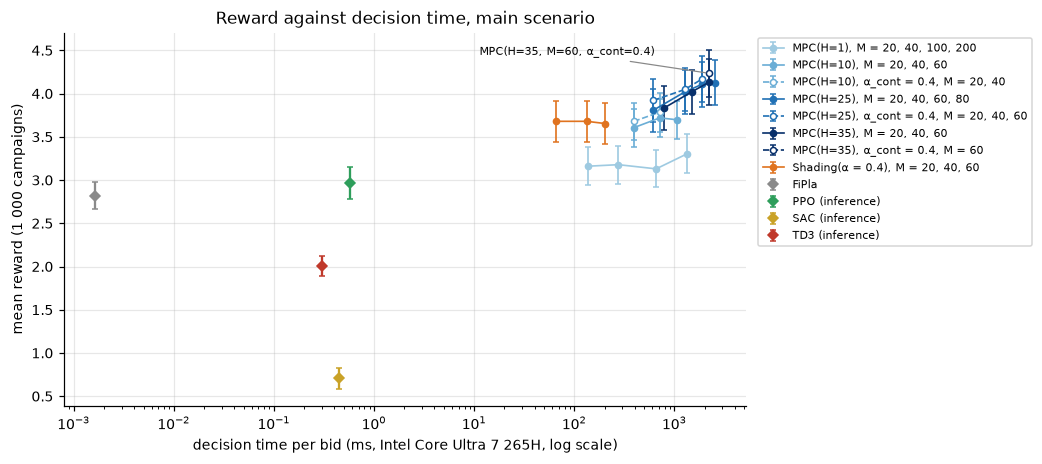

In [3]:
# reward against decision time (laptop column)
fig, ax = plt.subplots(figsize=(8, 4.4))
ok = [n for n in tab.index if key[n] in S]
for h, col in {1.0: "#9ecae1", 10.0: "#6baed6", 25.0: "#2171b5", 35.0: "#08306b"}.items():
    for cont in (False, True):
        names = sorted([n for n in ok if n.startswith(f"MPC(H={h:g},") and (("α_cont" in n) == cont)], key=lambda n: tab.loc[n, fast])
        if names:
            ax.errorbar([tab.loc[n, fast] for n in names], [S[n].mean() for n in names], yerr=[ci95(S[n]) for n in names],
                        fmt="o--" if cont else "o-", color=col, mfc="white" if cont else col, ms=4, lw=1.1, capsize=2,
                        label=f"MPC(H={h:g})" + (", α_cont = 0.4" if cont else "")
                              + ", M = " + ", ".join(re.search(r"M=(\d+)", n).group(1) for n in names))
names = sorted([n for n in ok if n.startswith("Shading")], key=lambda n: tab.loc[n, fast])
ax.errorbar([tab.loc[n, fast] for n in names], [S[n].mean() for n in names], yerr=[ci95(S[n]) for n in names],
            fmt="o-", color=COL["Shading"], ms=4, lw=1.1, capsize=2, label="Shading(α = 0.4), M = 20, 40, 60")
for n in ok:
    if n.startswith(("FiPla", "PPO", "TD3", "SAC")):
        ax.errorbar(tab.loc[n, fast], S[key[n]].mean(), yerr=ci95(S[key[n]]), fmt="D", color=color(n), ms=5, capsize=2, label=n)
best = max(ok, key=lambda n: S[key[n]].mean())
ax.annotate(best, (tab.loc[best, fast], S[best].mean()), xytext=(-150, 12), textcoords="offset points", fontsize=7,
            arrowprops=dict(arrowstyle="-", color="#888888", lw=0.8))
ax.set(xscale="log", xlabel=f"decision time per bid (ms, {fast.split(', ')[1]}, log scale)",
       ylabel="mean reward (1 000 campaigns)", title="Reward against decision time, main scenario")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
save(fig, "decision_time_vs_reward")

MPC's cost grows linearly with the number of rollouts $M$ and with the horizon $H$ (each rollout simulates the auctions of
the next $H$ time units), whereas its reward saturates around $H = 25$ and $M = 60$–$80$; the best setting,
MPC($H = 35$, $M = 60$, $\alpha_{\rm cont} = 0.4$), costs about 2 s per bid; one prediction of the MLP valuation
head costs well under a millisecond, and trained RL policies answer in a fraction of a millisecond.

## 2. MPC with an imperfect value estimate

MPC($H = 25$, $M = 80$), α ∈ {0.1, …, 1}, α_cont = 1, each variant on the 1000 campaigns and **paired with the unperturbed run**
(same campaigns, same rollout random numbers; only $\widehat V_0$ differs). $\widehat V_0$ is used for the first bid and for the
continuation bids of the rollouts.

| family | variants |
|---|---|
| noisy $\widehat V_0$ | every prediction multiplied by $e^{\sigma\varepsilon - \sigma^2/2}$, $\varepsilon \sim N(0, 1)$ (unbiased), σ ∈ {0.1, 0.25, 0.5, 1} |
| fewer training rollouts for the $V_0$ estimator | MLP 32-32 relu trained on 10, 30, 100, 300 FiPla episodes (main: 1000 episodes ≈ 42 000 auctions) |
| misspecified head | `nofatigue`: predicts with the fatigue context forced to $S_u(t) = 1, \forall t < T$ (ignores the carry-over effect) |
| Scaled $\widehat V_0$ | `scale0.5`, `scale2`: $\widehat V_0$ × 0.5, × 2; |
| planning rollouts M | M = 10, 20, 40, 60 vs 80 |

$\widehat V_0$ error: the value actually used at each decision (bid / α) against the oracle $V_0$ of that auction, on the auctions with
oracle $V_0 > $ `V0_MIN` (correlation, mean absolute error, mean error).

In [4]:
E = pd.read_csv(f"{D}/v0_errors.csv").set_index("variant")
Sv, _ = scores("v0_sensitivity")
Sm, _ = scores("main")
P = "MPC(H=25, M=80), "
# (family, variant, rewards per campaign, row of v0_errors.csv), in the order of the table above
ROWS = [("reference", "exact head (1000 episodes), M = 80", Sv[P + "exact MLP head (1000 FiPla episodes)"],
         "exact MLP head (1000 FiPla episodes)"),
        *[("noisy V̂0", f"σ = {x}", Sv[P + f"noisy V0, σ = {x}"], f"noisy V0, σ = {x}") for x in ("0.1", "0.25", "0.5", "1")],
        *[("fewer training rollouts for the V0 estimator", f"{n} episodes", Sv[P + f"MLP on {n} episodes"], f"MLP on {n} episodes")
          for n in (10, 30, 100, 300)],
        ("misspecified head", "nofatigue", Sv[P + "head ignoring fatigue (S = 1)"], "head ignoring fatigue (S = 1)"),
        ("misspecified head", "trained on survival-1", Sv[P + "head trained on survival-1"], "head trained on survival-1"),
        ("Scaled V̂0", "scale0.5", Sv[P + "V0 × 0.5"], "V0 × 0.5"),
        ("Scaled V̂0", "scale2", Sv[P + "V0 × 2"], "V0 × 2"),
        *[("planning rollouts M", f"M = {m}", Sm[f"MPC(H=25, M={m})"], None) for m in (10, 20, 40, 60)
          if f"MPC(H=25, M={m})" in Sm],   # M = 10: added when its run is complete
        ("baseline", "Shading(α = 0.4, M = 20)", Sv["Shading (α = 0.4, M=20)"], None),
        ("baseline", "FiPla", Sv["FiPla"], None)]
ref, shd, fip = ROWS[0][2], ROWS[-2][2], ROWS[-1][2]


def delta(r, base):   # paired on the 1000 campaigns
    return "—" if r is base else f"{(r - base).mean():+.3f} ± {ci95(r - base):.3f}"


tv = pd.DataFrame([{"family": f, "variant": v,
                    "corr. with oracle V0": E.loc[e, "corr_with_oracle_v0"] if e else np.nan,
                    "mean |V̂0 − V0|": E.loc[e, "mean_abs_error"] if e else np.nan,
                    "mean (V̂0 − V0)": E.loc[e, "mean_error"] if e else np.nan,
                    "mean reward": f"{r.mean():.3f} ± {ci95(r):.3f}",
                    "Δ vs reference": delta(r, ref), "Δ vs Shading(α = 0.4, M = 20)": delta(r, shd), "Δ vs FiPla": delta(r, fip)}
                   for f, v, r, e in ROWS]).set_index(["family", "variant"])
display(tv.style.format({"corr. with oracle V0": "{:.3f}", "mean |V̂0 − V0|": "{:.3f}", "mean (V̂0 − V0)": "{:+.3f}"}, na_rep="—")
          .set_caption("reference: MPC(H = 25, M = 80) with the 32-32 relu head trained on 1000 FiPla episodes; "
                       "the M rows use the same head (error columns not recomputed)."))

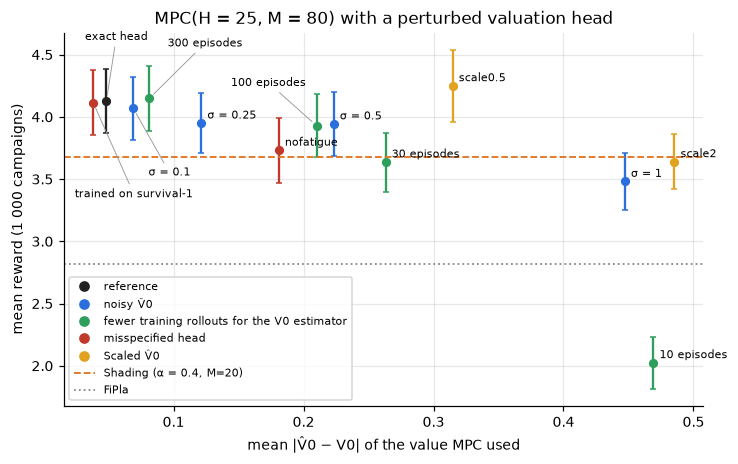

In [5]:
fam_col = {"reference": "#222222", "noisy V̂0": "#2a6fdb", "fewer training rollouts for the V0 estimator": "#2e9e5b",
           "misspecified head": "#c0392b", "Scaled V̂0": "#e0a21f"}
# crowded points: label moved away (offset in points) with a leader line
moved = {"trained on survival-1": (-12, -62), "exact head": (-14, 40), "σ = 0.1": (10, -44), "300 episodes": (12, 34),
         "100 episodes": (-56, 26)}
fig, ax = plt.subplots(figsize=(7.5, 4.4))
for f, v, r, e in ROWS:
    if f not in fam_col:   # M rows (same head as the reference) and baselines
        continue
    x = E.loc[e, "mean_abs_error"]
    ax.errorbar(x, r.mean(), yerr=ci95(r), fmt="o", color=fam_col[f], ms=5, capsize=2)
    lab = "exact head" if f == "reference" else v
    line = dict(arrowprops=dict(arrowstyle="-", color="0.6", lw=0.6, shrinkA=1, shrinkB=4)) if lab in moved else {}
    ax.annotate(lab, (x, r.mean()), xytext=moved.get(lab, (4, 3)), textcoords="offset points", fontsize=7, **line)
for fam, c in fam_col.items():
    ax.plot([], [], "o", color=c, label=fam)
for ref, ls in (("Shading", "--"), ("FiPla", ":")):
    k = find(Sv, ref)
    ax.axhline(Sv[k].mean(), color=color(k), ls=ls, lw=1.2, label=k)
ax.set(xlabel="mean |V̂0 − V0| of the value MPC used", ylabel="mean reward (1 000 campaigns)",
       title="MPC(H = 25, M = 80) with a perturbed valuation head")
ax.legend(loc="lower left")
save(fig, "v0_sensitivity")

- MPC is robust to small noise ($\sigma = 0.1$) and to a head trained on 300 episodes instead of 1 000. Noise
  $\sigma = 0.25$–$0.5$ or a head trained on 100 episodes costs about 0.2, and MPC still beats Shading; $\sigma = 1$ or
  30 episodes bring it to Shading's level, and a head trained on 10 episodes falls below FiPla.
- A misspecified head costs less than its value error suggests, because the rollouts simulate the true dynamics. 
- A head that ignores fatigue (−0.4) still bids as well as Shading. 
- A scale error is asymmetric: halving $\widehat V_0$ is harmless,  even slightly beneficial (the effective grid of bids becomes finer where the optimum lies), whereas doubling it costs about 0.5 (half of the candidate bids exceed the value, and the simulated continuation over-bids). 
- A head trained on the other survival scenario transfers without loss.
- Fewer planning rollouts: M = 60 is within noise of M = 80 (−0.02 ± 0.10), M = 40 costs 0.11, M = 20 costs 0.32 and
  M = 10 costs 0.52 ± 0.12, which brings MPC down to Shading's level (−0.07 ± 0.11).

## 3. Immediate rewards

`survival-second-price-exponential-immediate` is the main scenario without the delay between a won display and its
conversion. It separates two difficulties for RL: if PPO falls short of MPC in the main scenario because a reward arrives
several steps after the bid that caused it (delayed credit assignment), it should close the gap here; if the gap remains,
it comes from planning around fatigue.

| | main scenario (`survival-second-price-exponential`) | immediate (`survival-second-price-exponential-immediate`) |
|---|---|---|
| conversion probability of a won display | $f = \mathrm{clip}\big(S_u(t)\,(w_u^\top u)(w_x^\top x),\ 0,\ 1\big)$ | same $f$ |
| conversions per won display | at most 1 | at most 1 |
| time of the conversion | $t + s$, delay $s \sim \mathrm{Exp}(1)$ | $t$ (no delay) |
| conversion after the end $T$ of the campaign | lost | cannot happen |
| when the agent receives the reward | payment at the step of the win; conversion value at the first auction after $t + s$ | both at the step of the win |
| value of a won display (oracle $V_0$) | $f\,\big(1 - e^{-(T - t)}\big)$ | $f$ |
| preset: kernel / probe / `kappa_distribution` | `survival` (κ = 0, delayed intensity $f e^{-s}$) / `bernoulli` / `poisson` | `immediate-survival` (κ = $f$, no delayed intensity) / `null` / `bernoulli` |

Unchanged: the fatigue $S_u(t)$ (multiplicative, $c = 0.9$, $\beta = 1$), the second-price auction, the competing bid
LogNormal(−1, 1), the Poisson(1) arrivals, the horizon $T \sim$ Exp(mean 50), the user and display features.

- Rewards are slightly higher than in the main scenario (no conversion is lost at the end of the campaign), and the two
  scenarios do not share their random draws: compare the policies within a scenario.
- MPC uses an MLP valuation head (32-32 relu) retrained on the immediate scenario; the RL agents follow the same protocol
  as in the main benchmark.

In [6]:
ti = table("immediate", ["MPC(H=25, M=80)", "Shading", "FiPla"])
display(ti[~ti.index.str.startswith("Cooldown")])

,mean reward,"Δ vs MPC(H=25, M=80)","Δ vs Shading (best α = 0.4, M=20)",Δ vs FiPla
algorithm,,,,
"MPC(H=25, M=80)",4.369 ± 0.257,—,+0.547 ± 0.120,+1.407 ± 0.174
PPO [3.86 – 4.23],4.069 ± 0.223,-0.299 ± 0.101,+0.248 ± 0.102,+1.108 ± 0.145
"Shading (best α = 0.4, M=20)",3.822 ± 0.223,-0.547 ± 0.120,—,+0.860 ± 0.149
FiPla,2.961 ± 0.161,-1.407 ± 0.174,-0.860 ± 0.149,—
GreedyMyopic,2.908 ± 0.155,-1.460 ± 0.176,-0.913 ± 0.152,-0.053 ± 0.076
TD3 [0.00 – 3.93],1.309 ± 0.072,-3.060 ± 0.198,-2.513 ± 0.167,-1.652 ± 0.115
Constant (best b = 0.11),1.092 ± 0.103,-3.277 ± 0.209,-2.730 ± 0.186,-1.869 ± 0.147


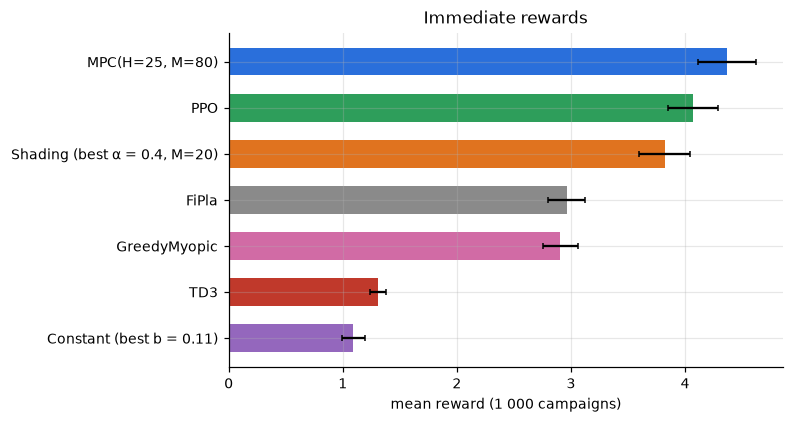

In [7]:
Si, _ = scores("immediate")
order = sorted([k for k in Si if not k.startswith("Cooldown")], key=lambda k: Si[k].mean())
fig, ax = plt.subplots(figsize=(6.5, 0.45 * len(order) + 0.8))
ax.barh(range(len(order)), [Si[k].mean() for k in order], xerr=[ci95(Si[k]) for k in order],
        color=[color(k) for k in order], height=0.6, capsize=2)
ax.set_yticks(range(len(order)))
ax.set_yticklabels(order)
ax.set(xlabel="mean reward (1 000 campaigns)", title="Immediate rewards")
save(fig, "immediate_rewards")

Without delayed rewards PPO improves on all the myopic baselines (it beats the best Shading) but still trails MPC: the gap
that remains is planning around fatigue, not the delay between a bid and its reward. TD3 (configuration selected by its
own search, 3 trainings) is unstable: one training reaches 3.93, above Shading, while the two others collapse to never
bidding, as 44 of its 96 search runs did.

## 4. Saturation and recency

Two kernels without user / display features: **saturation** $p = e^{-n/10}$ ($n$ = number of past wins) and **recency**
$p = 1 - e^{-0.5\tau}$ ($\tau$ = time since the last win); conversion delay Exp(0.5), competing bid LogNormal(−1, 1).
**DP optimum**: the exact Bayes-optimal policy (dynamic programming on the 1-D state), on the same campaigns. MPC uses
M = 60 unless stated (M = 80, 200: more rollouts); "α_cont" is the shading of the bids that continue each simulated future
after the first one (1 by default).

In [8]:
for exp in ("saturation", "recency"):
    print(f"\n{exp}")
    display(table(exp, ["DP optimum", "Shading", "FiPla"], gain=True))
A = pd.read_csv(f"{D}/dp_alpha_star.csv")
show = {"saturation-second-price-lognormal": [0, 2, 5, 10, 15, 20], "recency-second-price-lognormal": [0.25, 1, 2, 3, 5, 10]}
print("\nOptimal effective shading α* = b* / r by state (exact DP)")
display(pd.concat([A[(A["scenario"] == s) & A["value"].isin(v)].assign(scenario=s.split("-")[0])
                   for s, v in show.items()]).set_index(["scenario", "state", "value"])[["alpha_star"]].round(2).T)


saturation


,mean reward,"Δ vs Shading (best α = 0.5, M=20)",Δ vs FiPla,share of the DP gain over FiPla,Δ vs DP optimum
algorithm,,,,,
"Shading (best α = 0.5, M=20)",4.351 ± 0.158,—,+0.630 ± 0.122,+105%,+0.028 ± 0.085
DP optimum,4.323 ± 0.162,-0.028 ± 0.085,+0.602 ± 0.125,+100%,—
PPO [4.08 – 4.24],4.173 ± 0.143,-0.178 ± 0.076,+0.453 ± 0.104,+75%,-0.150 ± 0.072
"MPC(H=25, M=200)",4.066 ± 0.155,-0.285 ± 0.106,+0.345 ± 0.125,+57%,-0.257 ± 0.103
"MPC(H=25, M=60)",4.038 ± 0.154,-0.314 ± 0.108,+0.317 ± 0.120,+53%,-0.285 ± 0.110
"MPC(H=25, M=60, α_cont=0.4)",4.028 ± 0.156,-0.323 ± 0.108,+0.308 ± 0.125,+51%,-0.294 ± 0.113
"MPC(H=35, M=60)",3.994 ± 0.155,-0.357 ± 0.109,+0.273 ± 0.122,+45%,-0.329 ± 0.110
"MPC(H=25, M=60, α_cont=0.5)",3.994 ± 0.150,-0.358 ± 0.103,+0.273 ± 0.122,+45%,-0.329 ± 0.103
"MPC(H=25, M=60, α_cont=0.6)",3.967 ± 0.151,-0.384 ± 0.106,+0.246 ± 0.122,+41%,-0.356 ± 0.109



recency


,mean reward,"Δ vs Shading (best α = 0.6, M=20)",Δ vs FiPla,share of the DP gain over FiPla,Δ vs DP optimum
algorithm,,,,,
DP optimum,7.875 ± 0.529,+0.091 ± 0.117,+0.780 ± 0.183,+100%,—
"Shading (best α = 0.6, M=20)",7.784 ± 0.520,—,+0.689 ± 0.168,+88%,-0.091 ± 0.117
PPO + time since last win [7.63 – 7.66],7.643 ± 0.510,-0.141 ± 0.099,+0.548 ± 0.157,+70%,-0.232 ± 0.097
"MPC(H=25, M=80)",7.306 ± 0.496,-0.478 ± 0.137,+0.211 ± 0.168,+27%,-0.569 ± 0.142
"MPC(H=25, M=200)",7.277 ± 0.498,-0.507 ± 0.135,+0.182 ± 0.169,+23%,-0.598 ± 0.135
"MPC(H=25, M=60)",7.276 ± 0.493,-0.508 ± 0.140,+0.181 ± 0.169,+23%,-0.598 ± 0.141
"MPC(H=25, M=60, α_cont=0.7)",7.259 ± 0.500,-0.525 ± 0.141,+0.164 ± 0.176,+21%,-0.616 ± 0.143
"MPC(H=25, M=60, α_cont=0.5)",7.227 ± 0.487,-0.557 ± 0.137,+0.133 ± 0.174,+17%,-0.647 ± 0.146
"MPC(H=25, M=60, α_cont=0.6)",7.200 ± 0.483,-0.584 ± 0.148,+0.105 ± 0.182,+13%,-0.675 ± 0.151



Optimal effective shading α* = b* / r by state (exact DP)


scenario                  saturation                                \
state      wins before the auction n                                 
value                          0.00  2.00  5.00  10.00 15.00 20.00   
alpha_star                      0.39  0.42  0.46  0.55  0.66  0.76   

scenario                     recency                                
state      time since the last win τ                                
value                          0.25  1.00  2.00  3.00  5.00  10.00  
alpha_star                      0.64   0.6  0.57  0.55  0.54  0.53

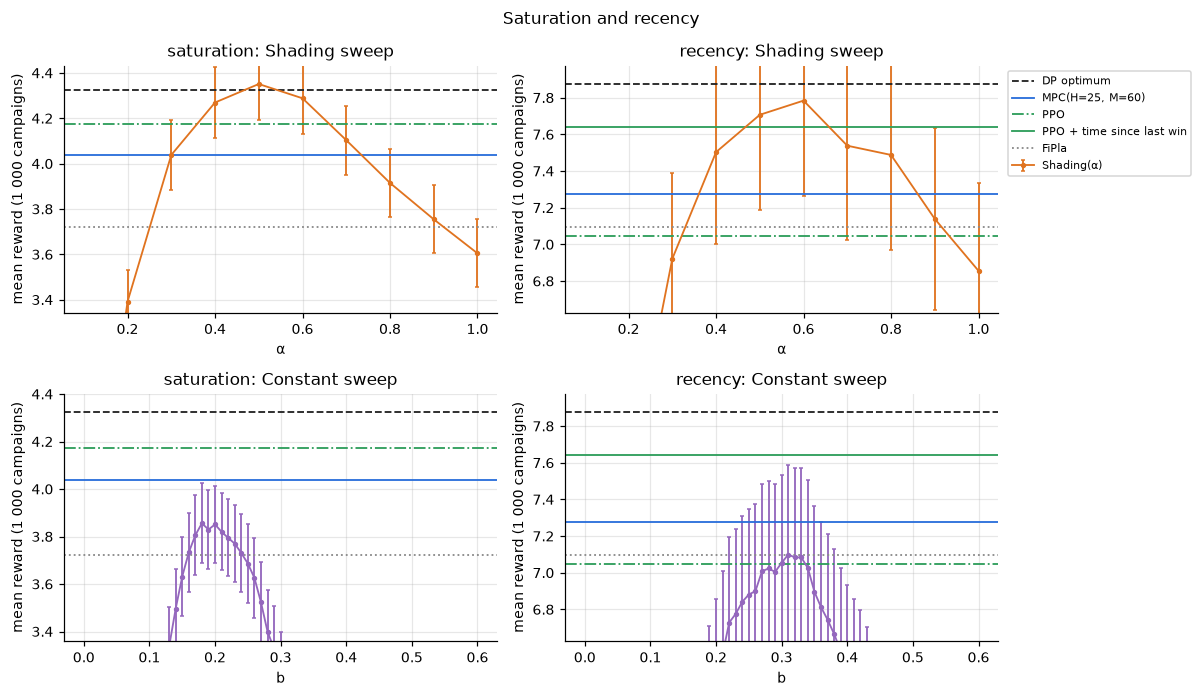

In [9]:
SW = pd.read_csv(f"{D}/sweeps.csv")
B = pd.read_csv(f"{D}/bids_by_state.csv")


def sweep_figure(exps, lines, name, title):
    # Shading α and Constant b sweeps, with the other policies as horizontal lines
    fig, axes = plt.subplots(2, len(exps), figsize=(5.5 * len(exps), 6.4))
    for j, exp in enumerate(exps):
        S_, _ = scores(exp)
        for i, pol in enumerate(("Shading", "Constant")):
            ax = axes[i, j]
            d = SW[(SW["experiment"] == exp) & (SW["policy"] == pol)].sort_values("param")
            if pol == "Constant":
                d = d[d["param"] <= 0.6]
            ax.errorbar(d["param"], d["mean"], yerr=d["ci95"], fmt="o-", ms=2.5, lw=1.2, capsize=1.5, color=COL[pol],
                        label=f"{pol}({'α' if pol == 'Shading' else 'b'})")
            for k, ls in lines:
                if k in S_:
                    ax.axhline(S_[k].mean(), color=color(k), ls=ls, lw=1.2, label=k)
            top = max([S_[k].mean() for k, _ in lines if k in S_] + [d["mean"].max()])
            bottom = S_[find(S_, "FiPla")].mean() - 0.6 * (top - S_[find(S_, "FiPla")].mean())
            ax.set(ylim=(min(bottom, d["mean"].max() - 0.2), top + 0.08 * (top - bottom)), title=f"{exp}: {pol} sweep",
                   xlabel="α" if pol == "Shading" else "b", ylabel="mean reward (1 000 campaigns)")
    axes[0, -1].legend(bbox_to_anchor=(1.01, 1), loc="upper left")
    fig.suptitle(title)
    plt.tight_layout()
    save(fig, name)


sweep_figure(("saturation", "recency"), [("DP optimum", "--"), ("MPC(H=25, M=60)", "-"), ("PPO", "-."),
             ("PPO + time since last win", "-"), ("FiPla", ":")], "saturation_recency_sweeps", "Saturation and recency")

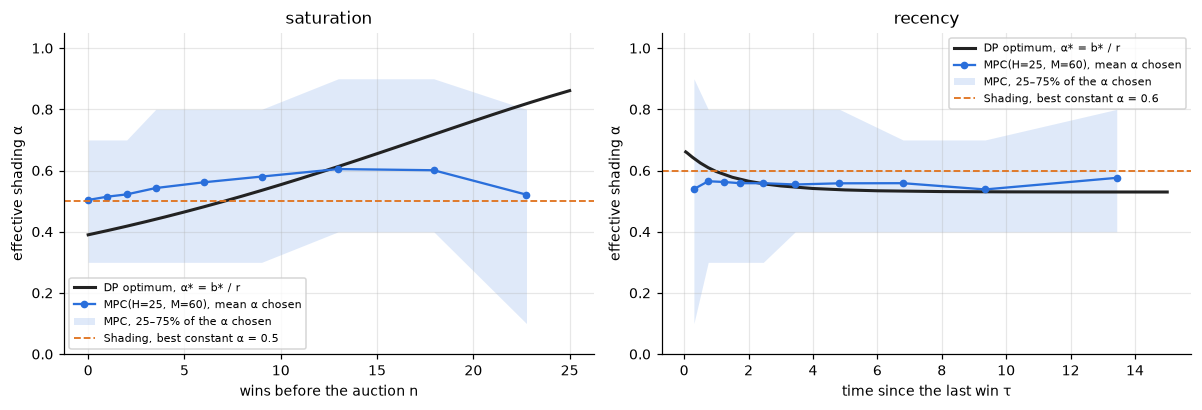

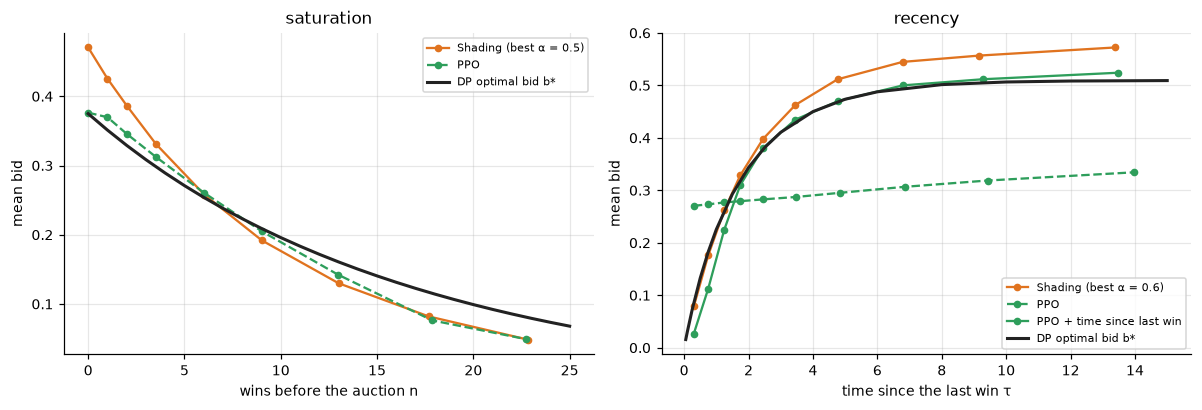

In [10]:
# DP optimal effective shading α* = b*/r against the α MPC chooses, by state
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, exp, xmax in zip(axes, ("saturation", "recency"), (25, 15)):
    a = A[(A["scenario"].str.startswith(exp)) & (A["value"] <= xmax)]
    ax.plot(a["value"], a["alpha_star"], color=COL["DP optimum"], lw=2, label="DP optimum, α* = b* / r")
    m = B[(B["experiment"] == exp) & B["policy"].str.startswith("MPC") & B["x"].notna()]
    ax.plot(m["x"], m["alpha_mean"], "o-", ms=4, color=COL["MPC"], label=f"{m['policy'].iloc[0]}, mean α chosen")
    ax.fill_between(m["x"], m["alpha_q25"], m["alpha_q75"], color=COL["MPC"], alpha=0.15, lw=0, label="MPC, 25–75% of the α chosen")
    a_sh = float(re.search(r"α = ([\d.]+)", find(scores(exp)[0], "Shading")).group(1))
    ax.axhline(a_sh, color=COL["Shading"], ls="--", lw=1.2, label=f"Shading, best constant α = {a_sh:g}")
    ax.set(title=exp, xlabel=m["state"].iloc[0], ylabel="effective shading α", ylim=(0, 1.05))
    ax.legend()
plt.tight_layout()
save(fig, "saturation_recency_alpha_by_state")

# mean bid by state: PPO with and without the time since the last win, Shading, DP optimal bid
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, exp, xmax in zip(axes, ("saturation", "recency"), (25, 15)):
    d = B[(B["experiment"] == exp) & B["x"].notna()]
    for pol in [p for p in d["policy"].unique() if p.startswith(("PPO", "Shading"))]:
        m = d[d["policy"] == pol]
        ax.plot(m["x"], m["mean_bid"], "o" + ("--" if pol == "PPO" else "-"), ms=4, color=color(pol), label=pol)
    a = A[(A["scenario"].str.startswith(exp)) & (A["value"] <= xmax)]
    ax.plot(a["value"], a["bid"], color=COL["DP optimum"], lw=2, label="DP optimal bid b*")
    ax.set(title=exp, xlabel=d["state"].iloc[0], ylabel="mean bid")
    ax.legend()
plt.tight_layout()
save(fig, "saturation_recency_bids_by_state")

**Why a constant shading is close to optimal here.** The DP shows that on these two kernels the optimal bid is almost a
constant fraction of the myopic value of the display: $\alpha^* = b^*/r$ stays between 0.39 and 0.66 for 0 to 15
previous wins in saturation (where most decisions are made), and between 0.53 and 0.64 in recency. The cost of a win (one more exposure,
or a reset of the recency clock) is roughly proportional to the value of the display, so a single well-chosen $\alpha$
captures almost all of the optimum, and Shading, whose $\alpha$ is tuned, is within noise of the DP.

**Why MPC is below Shading.** MPC re-chooses $\alpha$ at every auction by comparing the candidates on $M = 60$ simulated
futures. It is not a matter of how the simulated futures continue: continuing them with Shading ($\alpha_{\rm cont}$ near the
best Shading $\alpha$) instead of FiPla ($\alpha_{\rm cont} = 1$) changes nothing. The diagnostic at 100 fixed states per kernel
(table below) shows that MPC's objective has its optimum at the right place (estimated with $M = 2000$: $\alpha \approx 0.6$
in recency, as the DP and Shading) but is almost flat: the best and the second-best candidates differ by about 0.001,
whereas with $M = 60$ the estimated differences have a standard deviation of 0.04–0.07. MPC therefore picks the best
$\alpha$ about as often as a random choice would (10–12% of the decisions for 10 candidates), and this random shading wins
expensive auctions and loses cheap ones. More rollouts do not close the gap: MPC($H = 25$) with $M = 80$ and $M = 200$ is
within noise of $M = 60$ (saturation −0.10 ± 0.11 and +0.03 ± 0.12, recency +0.03 ± 0.14 and +0.00 ± 0.14) and stays below
Shading ($M = 200$: −0.29 ± 0.11 and −0.51 ± 0.14). The noise only falls as $1/\sqrt{M}$: scaled to $M = 200$, the
diagnostic still gives the best $\alpha$ in only about 19% (saturation) and 16% (recency) of the decisions.

**Why PPO is close to Shading on saturation but not on recency.** On saturation the state (number of wins) is an input
and PPO's bids follow the optimal bid closely. On recency PPO only sees the current time and the time of the last win (−1000 before
any win) as two separate inputs: its bid hardly depends on the time since the last win, and it performs like a constant
bid. Retrained with the time since the last win as an extra input ("PPO + time since last win", same configuration and
seeds), it gains 0.6 and comes close to Shading: the difficulty was the encoding of the state, not planning.

In [11]:
import os
if os.path.exists(f"{D}/mpc_decision_noise.csv"):
    N = pd.read_csv(f"{D}/mpc_decision_noise.csv")
    N["picks the best α"] = N["alpha_chosen"] == N["truth_argmax"]
    N["within ±0.1"] = (N["alpha_chosen"] - N["truth_argmax"]).abs() <= 0.1 + 1e-9
    print("MPC's choice of α at 100 fixed states per kernel (20 repetitions each; 'best' = argmax with M = 2000; "
          "mpc = MPC's estimator with M = 60, sync = the same with synchronised random numbers):")
    display(N.groupby(["scenario", "alpha_cont", "estimator"]).agg(
        states=("state", "nunique"), mean_regret=("regret", "mean"), picks_best=("picks the best α", "mean"),
        within_01=("within ±0.1", "mean"), spread_of_Q=("spread", "mean")).style.format(
        {"mean_regret": "{:.4f}", "picks_best": "{:.0%}", "within_01": "{:.0%}", "spread_of_Q": "{:.4f}"}))
else:
    print("MPC decision-noise diagnostic: not available yet")

MPC's choice of α at 100 fixed states per kernel (20 repetitions each; 'best' = argmax with M = 2000; mpc = MPC's estimator with M = 60, sync = the same with synchronised random numbers):


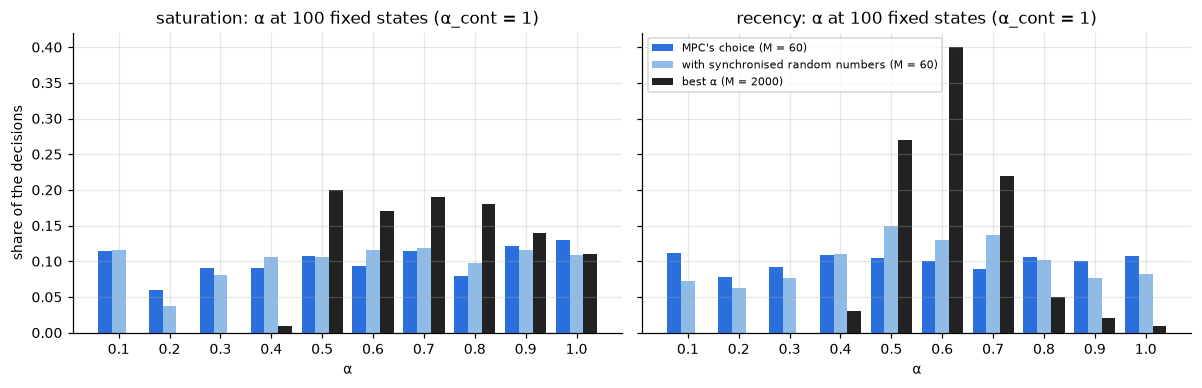

In [12]:
if os.path.exists(f"{D}/mpc_decision_noise.csv"):
    alphas = sorted(N["alpha_chosen"].unique())
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
    for ax, exp in zip(axes, ("saturation", "recency")):
        d = N[(N["scenario"] == exp) & (N["alpha_cont"] == 1.0)]
        series = {"MPC's choice (M = 60)": d[d["estimator"] == "mpc"]["alpha_chosen"],
                  "with synchronised random numbers (M = 60)": d[d["estimator"] == "sync"]["alpha_chosen"],
                  "best α (M = 2000)": d[d["estimator"] == "mpc"].drop_duplicates("state")["truth_argmax"]}
        for i, ((lab, v), c) in enumerate(zip(series.items(), (COL["MPC"], "#8fbbe8", COL["DP optimum"]))):
            share = v.value_counts(normalize=True).reindex(alphas, fill_value=0)
            ax.bar(np.array(alphas) + (i - 1) * 0.027, share.values, width=0.027, color=c, label=lab)
        ax.set(title=f"{exp}: α at 100 fixed states (α_cont = 1)", xlabel="α", xticks=alphas)
    axes[0].set_ylabel("share of the decisions")
    axes[1].legend()
    plt.tight_layout()
    save(fig, "saturation_recency_decision_noise")

## 5. Effective frequency and reminder

Two kernels where a win changes the value of the following displays in a way a proportional bid cannot follow, both with
the survival relevance $\mathrm{rel}(u, x) = \mathrm{clip}((\mathbf 1^\top u)(\mathbf 1^\top x), 0, 1)$:
**effective frequency** $p = \mathrm{rel} \cdot \sigma((n - 2)/0.7)\, e^{-n/10}$ (the first exposures rarely convert, the
peak is at $n = 4$ wins) and **reminder** $p = \mathrm{rel} \cdot [0.1 + 0.7\, r e^{1 - r}]$, $r = \tau / 2$ (a display
converts best about 2 time units after the previous win). MPC uses $\alpha \in \{0.1, \dots, 1, 1.5, 2, 3, 5\}$, since the
optimal bid can exceed $V_0$. "PPO + $\widehat V_0$": PPO observing the valuation head's $\widehat V_0$ and starting from a
policy at the bid scale.

In [13]:
for exp in ("effective-frequency", "reminder"):
    print(f"\n{exp}")
    display(table(exp, ["DP optimum", "Shading", "FiPla"], gain=True))


effective-frequency


,mean reward,"Δ vs Shading (best α = 1.25, M=20)",Δ vs FiPla,share of the DP gain over FiPla,Δ vs DP optimum
algorithm,,,,,
DP optimum,1.164 ± 0.108,+0.715 ± 0.101,+0.758 ± 0.097,+100%,—
PPO + V̂0 observation [0.93 – 0.98],0.961 ± 0.091,+0.513 ± 0.088,+0.556 ± 0.083,+73%,-0.202 ± 0.056
"MPC(H=25, M=80)",0.806 ± 0.100,+0.357 ± 0.093,+0.400 ± 0.094,+53%,-0.358 ± 0.086
"Shading (best α = 1.25, M=20)",0.449 ± 0.078,—,+0.043 ± 0.080,+6%,-0.715 ± 0.101
GreedyMyopic,0.437 ± 0.076,-0.011 ± 0.060,+0.032 ± 0.073,+4%,-0.726 ± 0.101
FiPla,0.405 ± 0.071,-0.043 ± 0.080,—,+0%,-0.758 ± 0.097
Constant (best b = 0.11),0.232 ± 0.054,-0.216 ± 0.077,-0.173 ± 0.077,-23%,-0.932 ± 0.100
PPO [0.00 – 0.03],0.009 ± 0.007,-0.440 ± 0.077,-0.397 ± 0.071,-52%,-1.155 ± 0.106
TD3 [0.00 – 0.00],0.000 ± 0.000,-0.449 ± 0.078,-0.405 ± 0.071,-53%,-1.164 ± 0.108



reminder


,mean reward,"Δ vs Shading (best α = 1.5, M=20)",Δ vs FiPla,share of the DP gain over FiPla,Δ vs DP optimum
algorithm,,,,,
DP optimum,2.560 ± 0.249,+0.889 ± 0.146,+1.250 ± 0.169,+100%,—
PPO + V̂0 observation [2.02 – 2.07],2.050 ± 0.204,+0.380 ± 0.121,+0.740 ± 0.134,+59%,-0.509 ± 0.113
"MPC(H=25, M=80)",2.022 ± 0.220,+0.352 ± 0.140,+0.712 ± 0.152,+57%,-0.538 ± 0.135
"Shading (best α = 1.5, M=20)",1.670 ± 0.203,—,+0.360 ± 0.135,+29%,-0.889 ± 0.146
FiPla,1.310 ± 0.164,-0.360 ± 0.135,—,+0%,-1.250 ± 0.169
GreedyMyopic,1.240 ± 0.159,-0.430 ± 0.132,-0.069 ± 0.107,-6%,-1.319 ± 0.166
"Cooldown (oracle V0, best τ = 1)",1.089 ± 0.139,-0.581 ± 0.145,-0.221 ± 0.097,-18%,-1.470 ± 0.183
Constant (best b = 0.22),0.657 ± 0.134,-1.014 ± 0.154,-0.653 ± 0.133,-52%,-1.903 ± 0.183
TD3 [0.00 – 1.45],0.482 ± 0.059,-1.189 ± 0.166,-0.828 ± 0.131,-66%,-2.078 ± 0.206


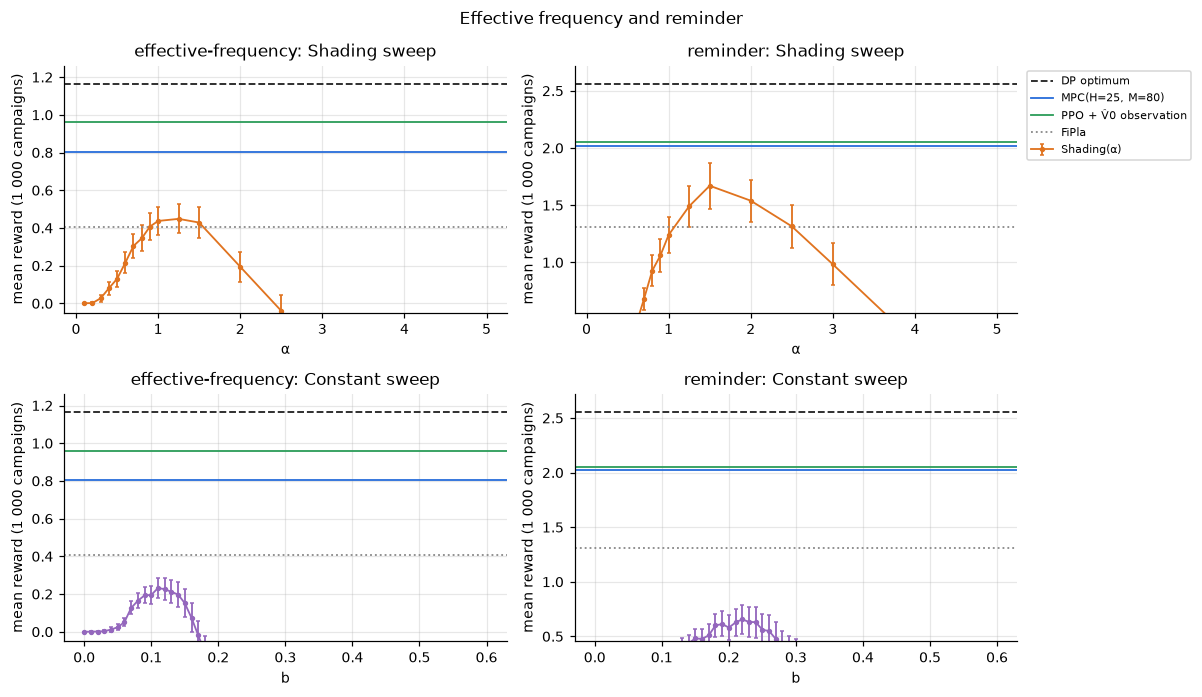

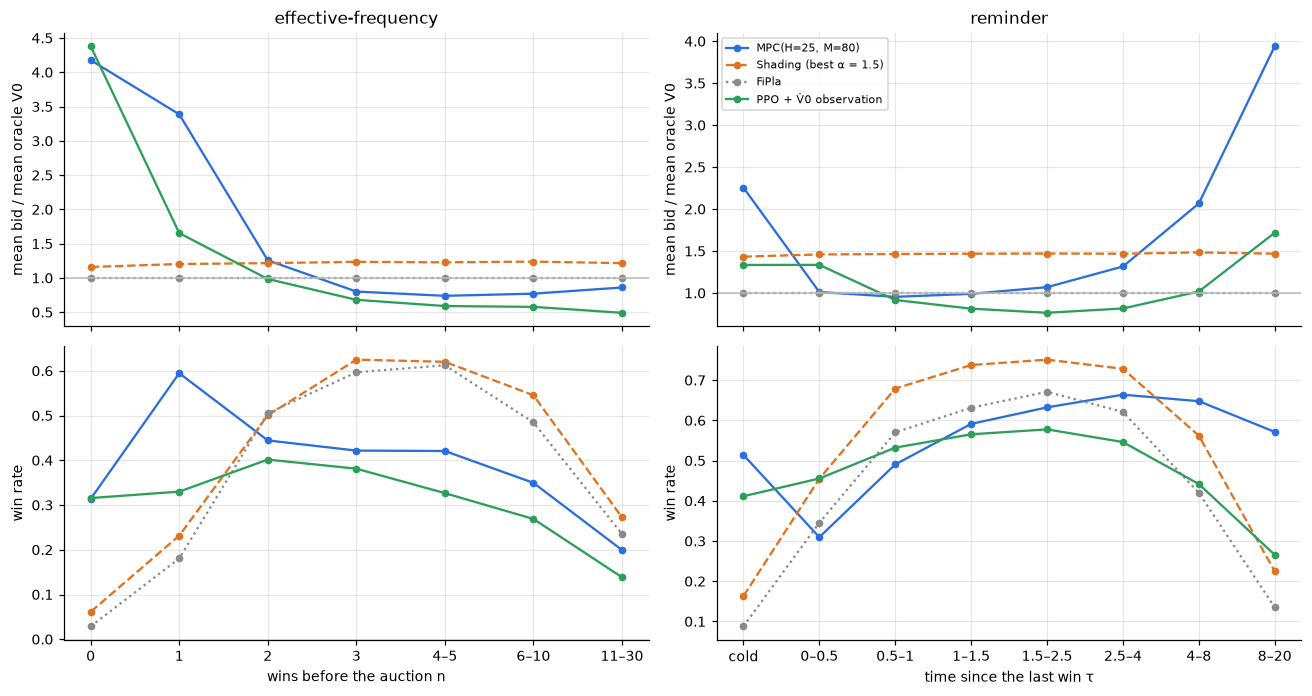

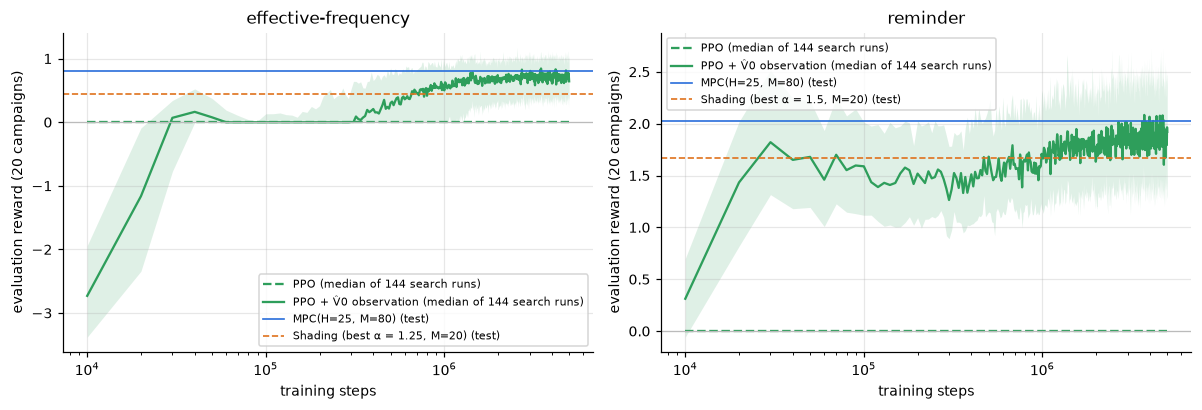

In [14]:
sweep_figure(("effective-frequency", "reminder"), [("DP optimum", "--"), ("MPC(H=25, M=80)", "-"), ("PPO + V̂0 observation", "-"),
             ("FiPla", ":")], "planning_kernels_sweeps", "Effective frequency and reminder")


def bin_label(b, state):
    if b == "cold":
        return "cold"
    lo, hi = (float(x) for x in b.strip("(]").split(","))
    if state.startswith("wins"):
        lo, hi = int(lo + 0.5), int(hi - 0.5)
        return str(lo) if lo == hi else f"{lo}–{hi}"
    return f"{lo:g}–{hi:g}"


fig, axes = plt.subplots(2, 2, figsize=(12, 6.4), sharex="col")
for j, exp in enumerate(("effective-frequency", "reminder")):
    d = B[B["experiment"] == exp]
    order = (["cold"] if (d["bin"] == "cold").any() else []) + list(d[d["bin"] != "cold"].sort_values("x").drop_duplicates("bin")["bin"])
    for pol in [p for p in d["policy"].unique() if p != "PPO"]:
        m = d[d["policy"] == pol].set_index("bin").reindex(order)
        ls = "-" if pol.startswith(("MPC", "PPO")) else ("--" if pol.startswith("Shading") else ":")
        axes[0, j].plot(range(len(order)), m["bid_over_v0"], "o" + ls, ms=4, color=color(pol), label=pol)
        axes[1, j].plot(range(len(order)), m["win_rate"], "o" + ls, ms=4, color=color(pol), label=pol)
    axes[0, j].axhline(1, color="#bbbbbb", lw=1)
    axes[0, j].set(title=exp, ylabel="mean bid / mean oracle V0")
    axes[1, j].set(xlabel=d["state"].iloc[0], ylabel="win rate")
    axes[1, j].set_xticks(range(len(order)))
    axes[1, j].set_xticklabels([bin_label(b, d["state"].iloc[0]) for b in order])
axes[0, 1].legend()
plt.tight_layout()
save(fig, "planning_kernels_bids_by_state")

C = pd.read_csv(f"{D}/ppo_curves.csv")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, exp in zip(axes, ("effective-frequency", "reminder")):
    S_, _ = scores(exp)
    for pol, ls in (("PPO", "--"), ("PPO + V̂0 observation", "-")):
        c = C[(C["experiment"] == exp) & (C["policy"] == pol)]
        ax.plot(c["timesteps"], c["median"], ls=ls, color=color(pol), lw=1.5, label=f"{pol} (median of {c['runs'].iloc[0]} search runs)")
        ax.fill_between(c["timesteps"], c["q25"], c["q75"], color=color(pol), alpha=0.15, lw=0)
    for k, ls in (("MPC(H=25, M=80)", "-"), (find(S_, "Shading"), "--")):
        ax.axhline(S_[k].mean(), color=color(k), ls=ls, lw=1.1, label=f"{k} (test)")
    ax.axhline(0, color="#bbbbbb", lw=0.8)
    ax.set(xscale="log", title=exp, xlabel="training steps", ylabel="evaluation reward (20 campaigns)")
    ax.legend()
plt.tight_layout()
save(fig, "planning_kernels_ppo_curves")

Here the first exposures are an investment (effective frequency) and the value of a win lies in its timing (reminder):
the optimum bids well above the myopic value in some states and below it in others. A constant or proportional bid cannot
do this, and the DP is far above the best Shading. MPC beats every baseline and captures about half of the DP's gain over
FiPla, bidding several times $V_0$ on the first exposures and on cold contacts. PPO with its default setup stops bidding
altogether: its Gaussian action is clipped at 0, early losses push its mean below 0, after which every sample bids 0 and
the gradient vanishes. TD3 collapses in the same way: with the configuration selected by its search, it bids 0 in its 3
trainings on effective frequency and in 2 of its 3 trainings on reminder (the third reaches 1.45). Given the valuation head's $\widehat V_0$ as an
input and a starting policy at the bid scale, PPO learns both kernels: it ends above MPC on effective frequency and level
with it on reminder.

## 6. Valuation-head architecture

MLP valuation heads $\widehat V_0$ of different sizes (hidden layers 32-32, 64-64, 128-128) and activations (ReLU, Leaky ReLU)
on the main scenario, 3 initialisation seeds each; same data as the head used by MPC (1 000 FiPla campaigns, environment
seeds 10 000–10 999, the same 85% / 15% train / validation split), Adam, learning rate $10^{-3}$, batch 256, 500 epochs.
Test: 200 new FiPla campaigns (seeds 30 000–30 199). Curves: mean over the seeds, band = min–max.

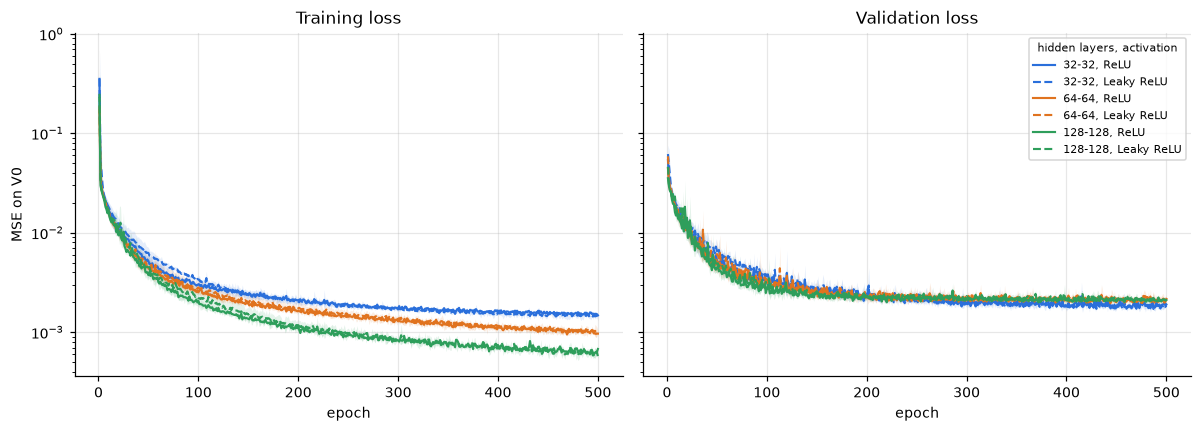

In [15]:
MC = pd.read_csv(f"{D}/mlp_arch_curves.csv")
size_col = {"32-32": "#2a6fdb", "64-64": "#e0731f", "128-128": "#2e9e5b"}
names = {"relu": "ReLU", "leaky_relu": "Leaky ReLU"}
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, split, title in ((axes[0], "train", "Training loss"), (axes[1], "val", "Validation loss")):
    for h in size_col:
        for act, ls in (("relu", "-"), ("leaky_relu", "--")):
            g = MC[(MC["split"] == split) & (MC["hidden"] == h) & (MC["activation"] == act)]
            ax.plot(g["epoch"], g["mean"], color=size_col[h], ls=ls, lw=1.4, label=f"{h}, {names[act]}")
            ax.fill_between(g["epoch"], g["min"], g["max"], color=size_col[h], alpha=0.12, lw=0)
    ax.set(title=title, xlabel="epoch", yscale="log")
axes[0].set_ylabel("MSE on V0")
axes[1].legend(title="hidden layers, activation", title_fontsize=7)
plt.tight_layout()
save(fig, "mlp_architectures_loss")
display(pd.read_csv(f"{D}/mlp_arch_summary.csv").set_index(["architecture", "activation"])[
    ["params", "final_train_mse", "final_val_mse", "best_val_epoch", "test_mse", "test_corr", "train_minutes"]]
    .style.format({"final_train_mse": "{:.5f}", "final_val_mse": "{:.5f}", "test_mse": "{:.5f}", "test_corr": "{:.3f}",
                   "best_val_epoch": "{:.0f}", "train_minutes": "{:.1f}"}))

Larger heads fit the training set better but not the validation or test sets (slight overfitting: their best validation
epoch comes earlier), and the activation makes no difference: the 32-32 ReLU head used by MPC has the lowest test error.